<a href="https://colab.research.google.com/github/Jayadeep19/pytorch/blob/master/pytorch/MLP/Multi_layer_perceptron_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MLP- classification

- In this notebook, we'l implement a MLP for classification task of MNIST dataset. (we have already built a classifier for this dataset in [previous notebook](https://github.com/Jayadeep19/pytorch/blob/master/pytorch/basics/Models_and_optimizers.ipynb))
- To understand the dataset more, visit previous notebook.

In [1]:
# Import all the libraries necessary

import numpy
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data.dataloader import DataLoader
from torch.utils.data.dataset import Dataset
# we uses MNIST dataset from keras before, now we can use the dataset by pytorch.
from torchvision.datasets import MNIST


- let us see two ways to download the dataset.
  1. using keras first download the dataset in numpy->make tensors->make_datasets using `from torch.utils.data.dataset import Dataset`
  2. using pytorch directly

## using Keras

In [2]:
from keras.datasets import mnist
(train_X, train_y), (test_X, test_y) = mnist.load_data()

# convert them to tensors:
train_X_tensor = torch.from_numpy(train_X.reshape(60000,784)).float()
train_y_tensor = torch.from_numpy(train_y).long()  # pytorch optimizers expect long datatype for labels
test_X_tensor = torch.from_numpy(test_X.reshape(10000,784)).float()
test_y_tensor = torch.from_numpy(test_y).long()

# To download the dataset from pytoch use
'''
train = MNIST(data_set_root, train=True,  download=True, transform=transforms.ToTensor())
test  = MNIST(data_set_root, train=False, download=True, transform=transforms.ToTensor())
'''

'\ntrain = MNIST(data_set_root, train=True,  download=True, transform=transforms.ToTensor())\ntest  = MNIST(data_set_root, train=False, download=True, transform=transforms.ToTensor())\n'

In [3]:
batch_size = 256

class mnist_dataset(Dataset):
  def __init__(self, X, y):
    super().__init__()
    self.X = X
    self.y = y

  def __len__(self):
    return self.X.shape[0]

  def __getitem__(self, idx):
    return self.X[idx], self.y[idx]

#create the datasets
train = mnist_dataset(train_X_tensor, train_y_tensor)
test = mnist_dataset(test_X_tensor, test_y_tensor)

In [4]:
#explore dataset
print('train X:',train.X.shape, 'train y:', train.y.shape)
print('test X:',test.X.shape, 'test y:', test.y.shape)

train X: torch.Size([60000, 784]) train y: torch.Size([60000])
test X: torch.Size([10000, 784]) test y: torch.Size([10000])


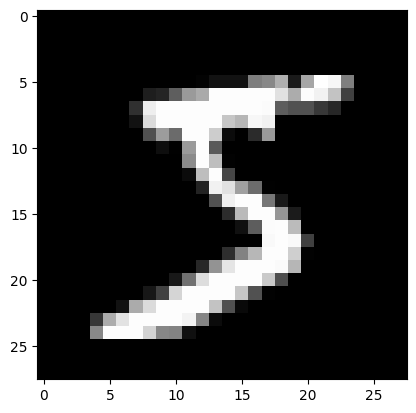

In [5]:
plt.imshow(train.X[0].reshape(28,28), cmap = 'gray')

In [6]:
train_loader = DataLoader(dataset = train, batch_size = batch_size, shuffle = True)
test_loader = DataLoader(dataset = test, batch_size = batch_size, shuffle = True)

In [7]:
train_loader.dataset

In [8]:
images = next(iter(train_loader.dataset.X))
labels = next(iter(train_loader.dataset.y))
print("The input data shape is :\n", images.shape)
print("The target output data shape is :\n", labels.shape)

The input data shape is :
 torch.Size([784])
The target output data shape is :
 torch.Size([])


In [9]:
# we'll use gpu if available
gpu_id = 0
device = torch.device(gpu_id if torch.cuda.is_available() else 'cpu')

## using pytorch

In [10]:
import torchvision.transforms as transforms

# 1. Define your data transformation (e.g., converting to Tensors)
transform = transforms.Compose([transforms.ToTensor()])

# 2. Download and load the datasets at runtime
train_dataset = MNIST(
    root='./data',      # Directory where the files will be temporarily cached
    train=True,         # Loads the 60,000 training images
    download=True,      # Tells PyTorch to fetch the files online if missing
    transform=transform
)

test_dataset = MNIST(
    root='./data',
    train=False,        # Loads the 10,000 test images
    download=True,
    transform=transform
)

# 3. Wrap in DataLoaders for training loops
train_loader_torch = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
test_loader_torch = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False)


In [11]:
# this is different to the train_loder because the keras dataset is flattened numpy array we can reshape it to 28*28 again
train_loader_torch.dataset.data.shape

torch.Size([60000, 28, 28])

In [12]:
train_loader_torch.dataset.targets.shape

torch.Size([60000])

## define our architecture for the model.



In [13]:
class mlp_classifier(nn.Module):
  def __init__(self, num_classes, hidden_size):
    super(mlp_classifier, self).__init__()
    self.fc1 = nn.Linear(784, hidden_size)
    self.fc2 = nn.Linear(hidden_size, 256)
    self.fc3 = nn.Linear(256, 256)
    self.fc4 = nn.Linear(256, num_classes)

  def forward(self,x):
    '''
    We are using keras dataset (60000, 784) here so, we dont need to flatten the images again
    meaning: we can pass the dataset as size (BS, 784)
    -If we want to use the pytorch dataset (60000, 28, 28), we must reshape the images here to (BS, 784)
    '''
    x = F.relu(self.fc1(x))
    x = F.relu(self.fc2(x))
    x = F.relu(self.fc3(x))
    x = self.fc4(x)
    return x

In [14]:
# define the hyper parameters

lr = 0.001

mnist_classifier = mlp_classifier(num_classes=10, hidden_size=512).to(device)

loss_fn = nn.CrossEntropyLoss()

optimizer = optim.Adam(mnist_classifier.parameters(), lr = lr)

epochs = 7

print(mnist_classifier)


mlp_classifier(
  (fc1): Linear(in_features=784, out_features=512, bias=True)
  (fc2): Linear(in_features=512, out_features=256, bias=True)
  (fc3): Linear(in_features=256, out_features=256, bias=True)
  (fc4): Linear(in_features=256, out_features=10, bias=True)
)


In [15]:
# let us make a function to train our model first for 1 epoch
def train_epoch(model, train_loader, optimizer, loss_fn, loss_logger):
  for i , (mini_batch, targets) in enumerate(tqdm(train_loader, desc = "training", leave = False)):
    outputs = model(mini_batch.to(device))

    loss = loss_fn(outputs, targets.to(device))

    loss.backward()
    loss_logger.append(loss.item())
    optimizer.step()
    optimizer.zero_grad()

  return model, optimizer, loss_logger



#train_epoch(mnist_classifier, train_loader, optimizer, loss_fn, train_loss)

In [16]:
# now also let us write a function to evluate our model
def test_model(model, test_loader, loss_fn, loss_logger):

  with torch.no_grad():
    #to calculate the accuracy of our model we have to accumulate the accuracy over multiple steps
    correct_predictions = 0
    total_predictions = 0
    #loop over the test_loader
    for i, (mini_batch, targets) in enumerate(tqdm(test_loader, desc = "testing", leave = False)):
      predictions = model(mini_batch.to(device))

      #we have the shape of the predictions as (BS, 10). So we have to get the max probability score for each image from the output (see text below this cell)
      _, indexes = torch.max(predictions, 1)  # get the max value from each row, in our case, the index is target class [0-9]
      correct_predictions += (indexes == targets.to(device)).sum().item()
      total_predictions += targets.shape[0]

      loss = loss_fn(predictions, targets.to(device))
      loss_logger.append(loss.item())

    #calculate the accuracy of the model
    acc = (correct_predictions / total_predictions)*100


  return loss_logger, acc


#prediction, target = test_model(mnist_classifier, test_loader, loss_fn, test_loss)

- example:
- ```
    prediction, target = test_model(mnist_classifier, test_loader, loss_fn, test_loss)
    ```
    with
- ```python
    val, ind = torch.max(prediction,1)
    print(val)
    print('/n', ind)
    print('/n',target)
    print(ind == target)
    ```
    gives
> - tensor([ 6.6639,  5.2679, 10.8452,  6.1948,  5.5253,  9.9135,  4.6468,  6.9271, 7.6109,  7.4263,  5.8467, 12.1693,  4.4044,  5.8334,  5.6897,  7.6734])
> - tensor([7, 7, 7, 7, 6, 6, 6, 7, 6, 6, 6, 6, 7, 7, 6, 7])
> - tensor([3, 5, 0, 8, 4, 6, 4, 5, 6, 9, 8, 8, 1, 6, 1, 4])
> - tensor([False, False, False, False, False,  True, False, False,  True,False,False, False, False, False, False, False])

- Meaning, we can just perform torch.max() to obtain the max probability per prediction and its index is the target value (prediction)[0-9]

In [17]:
#initilize loss loggers
train_loss_logger = []
test_loss_logger = []
model_acc = []

In [18]:
# Now we can train for the desired epochs
for i in tqdm(range(epochs), desc= 'Epoch', leave = False):
  model, optimizer, train_loss = train_epoch(mnist_classifier, train_loader, optimizer, loss_fn, train_loss_logger)
  test_loss, acc = test_model(mnist_classifier, test_loader, loss_fn, test_loss_logger)
  model_acc.append(acc)


Epoch:   0%|          | 0/7 [00:00<?, ?it/s]

training:   0%|          | 0/235 [00:00<?, ?it/s]

testing:   0%|          | 0/40 [00:00<?, ?it/s]

training:   0%|          | 0/235 [00:00<?, ?it/s]

testing:   0%|          | 0/40 [00:00<?, ?it/s]

...

testing:   0%|          | 0/40 [00:00<?, ?it/s]

training:   0%|          | 0/235 [00:00<?, ?it/s]

testing:   0%|          | 0/40 [00:00<?, ?it/s]

training:   0%|          | 0/235 [00:00<?, ?it/s]

testing:   0%|          | 0/40 [00:00<?, ?it/s]

## Plot the losses

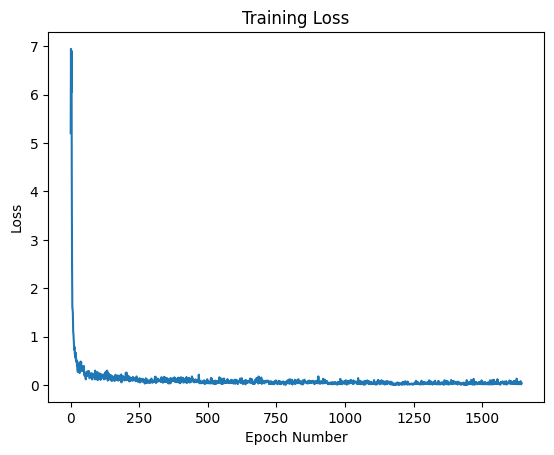

In [19]:
plt.title('Training Loss')
plt.xlabel('Epoch Number')
plt.ylabel('Loss')
plt.plot(train_loss)

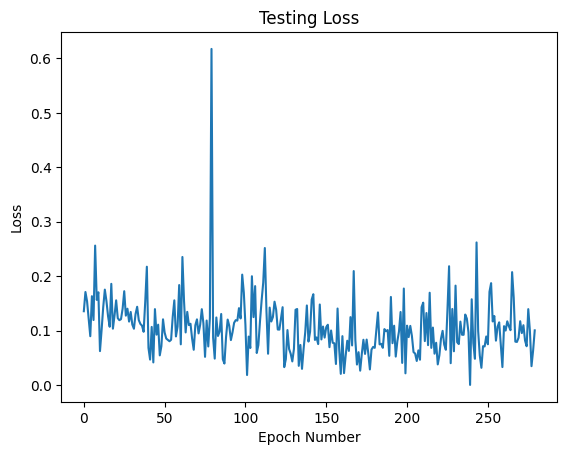

In [20]:
plt.title('Testing Loss')
plt.xlabel('Epoch Number')
plt.ylabel('Loss')
plt.plot(test_loss)

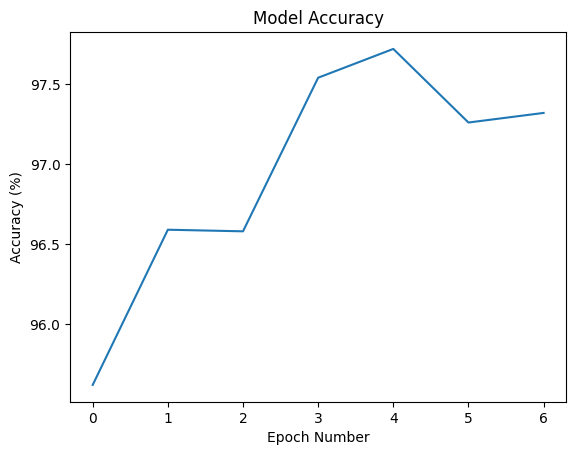

In [21]:
plt.title('Model Accuracy')
plt.xlabel('Epoch Number')
plt.ylabel('Accuracy (%)')
plt.plot(model_acc)